# 8 · Knowledge-graph visualization  (per article)

Draws the KG produced by the pipeline for one article in two forms — a **static** matplotlib/networkx
figure (`results/<id>/kg_<id>.png`) and an **interactive** self-contained pyvis HTML
(`results/<id>/kg_<id>.html`) you can drag, zoom, and hover.

The loader **auto-detects** the graph shape from the file named in `REL_FILES`:

- **Binary** (`relations_ext*.json`, nb7) — entities as nodes, `subject → property → object` triples
  as edges. Nodes coloured by **entity type**; edges **solid** for schema.org properties, **dashed**
  for minted `ex:` properties.
- **Reified / event-centric** (`reified_graph.json`, nb6b) — the **n-ary nodes** (Event / Observation /
  Claim) become **★ star nodes** coloured by node kind, with **main events outlined**; each **role**
  is an edge n-ary-node→participant labelled with the role and **dashed for `ex` (extension)** terms,
  solid for schema.org ones. `cause`/`partOf` roles that point at another n-ary node form the backbone;
  `value_text`-only roles show as small box literals (toggle `INCLUDE_LITERALS`); `binary_relations`
  render as plain edges whose endpoints may be entities **or** n-ary nodes.

Switch views by editing `REL_FILES` in the config cell — everything below works unchanged for both.

In [1]:
# --- resolve Phase2_LLM_Extraction root (works whether this notebook lives at the
# project root or under notebooks/<track>/) so results/ & dataset/ paths are stable.
from pathlib import Path
def _find_root(start: Path = None):
    start = (start or Path.cwd()).resolve()
    for p in (start, *start.parents):
        if (p / 'results').is_dir() and (p / 'dataset').is_dir():
            return p
    return start
ROOT = _find_root()
# make Path writes create missing parent dirs (results/ now has sub-folders like
# two_staged/1_entities/); guarded so re-running the cell never double-wraps.
import pathlib as _pl
if not getattr(_pl.Path.write_text, '_mkparents', False):
    _wt, _wb = _pl.Path.write_text, _pl.Path.write_bytes
    def write_text(self, *a, **k):
        self.parent.mkdir(parents=True, exist_ok=True); return _wt(self, *a, **k)
    def write_bytes(self, *a, **k):
        self.parent.mkdir(parents=True, exist_ok=True); return _wb(self, *a, **k)
    write_text._mkparents = write_bytes._mkparents = True
    _pl.Path.write_text, _pl.Path.write_bytes = write_text, write_bytes

In [2]:
# --- Config -------------------------------------------------------------------------------
from pathlib import Path

RESULTS_DIR = ROOT / "results"     # per-article outputs from nb6b (n-ary) or nb7 (binary)
ARTICLE_ID  = "art1"              # which article to draw

# Which graph file to read. The loader AUTO-DETECTS the shape:
#   - nary_graph.json (nb6b)     -> n-ary nodes + open `relations` (relation_phrase)  [event-centric view]
#   - relations_ext*.json (nb7)  -> flat subject/property/object triples              [binary view]
# List them in priority order; the first that exists per article wins.
#   n-ary:   REL_FILES = ["two_staged/3_nary_graph/nary_graph.json"]
#   binary:  REL_FILES = ["two_staged/2_binary_relations/relations_consolidated.json", "two_staged/2_binary_relations/relations.json"]
REL_FILES = ["e2e/nary_graph_dedup.json"]


INCLUDE_ISOLATED = True          # False: only nodes that take part in >=1 edge (clearer graph)
INCLUDE_LITERALS = True          # (reified only) draw value_text-only roles as small box nodes — old schema
MAX_TYPE_COLORS  = 8              # distinct type colours; rarer types fold into a neutral "Other"
SHOW_EDGE_LABELS = True           # draw the relation/property name on each edge in the STATIC figure
STATIC_FIGSIZE   = (16, 11)
LAYOUT_SEED      = 42             # reproducible spring layout

# Interactive (pyvis) readability knobs — bump these if labels look small when zoomed out.
NODE_FONT_SIZE   = 40            # node label size (px)
EDGE_FONT_SIZE   = 30            # edge (relation) label size (px)
PYVIS_SPRING     = 150           # spring length — larger = more spread out
PYVIS_HEIGHT     = "900px"       # canvas height

def rel_path(aid):
    for name in REL_FILES:
        p = RESULTS_DIR / aid / name
        if p.exists():
            return p
    return None

print("article:", ARTICLE_ID, "| reads first present of:", REL_FILES)

article: art1 | reads first present of: ['e2e/nary_graph_dedup.json']


In [3]:
# First run only.
%pip install -q networkx matplotlib pyvis

Note: you may need to restart the kernel to use updated packages.


## 1. Load the graph (self-contained from nb7's relations file)

In [4]:
import json
from collections import Counter

LAST_SRC = ""     # basename of the file the most recent load_kg() read — drives the output filename (kg_stem)

def load_binary(data, cards, include_isolated):
    """nb7 flat relations -> (nodes, edges).  Original behaviour, unchanged."""
    edges = []
    for r in data.get("relations", []):
        edges.append({
            "s": r.get("subject_id"), "o": r.get("object_id"),
            "s_text": r.get("subject_text"), "o_text": r.get("object_text"),
            "s_type": r.get("subject_type"), "o_type": r.get("object_type"),
            "property": r.get("property"), "source": r.get("property_source"),
            "phrases": r.get("relation_phrases", []),
            "evidence": (r.get("evidence") or [None])[0],
            "confidence": r.get("confidence"),
        })
    nodes = {}
    def _node(eid, ft=None, fy=None):
        c = cards.get(eid, {})
        nodes[eid] = {"label": c.get("text") or ft or eid, "type": c.get("type") or fy or "Unknown",
                      "type_source": c.get("type_source"), "type_parent": c.get("type_parent")}
    for e in edges:
        _node(e["s"], e["s_text"], e["s_type"]); _node(e["o"], e["o_text"], e["o_type"])
    used = {e["s"] for e in edges} | {e["o"] for e in edges}
    if include_isolated:
        for eid in cards:
            if eid not in nodes: _node(eid)
    else:
        nodes = {i: v for i, v in nodes.items() if i in used}
    return nodes, edges

def load_nary(data, cards, include_isolated):
    """nb6b nary_graph.json -> (nodes, edges).  N-ary nodes (Event/Observation/Claim) are star nodes;
       the top-level `relations` list gives the edges. Each relation's label is its canonical `property`
       once nb7 has run, else the OPEN `relation_phrase`. Edge source is one of: "schema.org" (solid),
       "vocab" (minted -> dashed), or "open" (not yet canonicalized -> solid neutral). Endpoints may be
       entities (`E..`) or n-ary nodes (`EV../OBS../CL..`). Also accepts the OLD `hubs`+roles schema."""
    nodes, edges = {}, []
    narys = data.get("nary_nodes") or data.get("hubs") or []

    def ent(eid):
        if eid and eid not in nodes:
            c = cards.get(eid, {})
            nodes[eid] = {"label": c.get("text") or eid, "type": c.get("type") or "Unknown",
                          "type_source": c.get("type_source"), "type_parent": c.get("type_parent")}
        return eid
    def ref(idv):                                                  # id may be an n-ary node OR an entity
        return idv if idv in nodes else ent(idv)

    for n in narys:                                                # 1) n-ary nodes as stars
        kind = n.get("node_kind") or n.get("hub_kind")
        nodes[n["id"]] = {"label": n.get("label") or n["id"], "type": kind or "N-aryNode",
                          "is_nary": True, "shape": "star",
                          "nary_kind": kind, "nary_type": n.get("type"),
                          "nary_type_source": n.get("type_source"), "nary_type_parent": n.get("type_parent"),
                          "is_main": bool(n.get("is_main")),
                          "evidence": (n.get("evidence") or [None])[0]}

    open_rels = data.get("relations")
    if open_rels is not None:                                      # 2a) NEW schema: top-level relations
        for r in open_rels:
            s = ref(r.get("subject_id")); o = ref(r.get("object_id"))
            phrase = r.get("relation_phrase"); prop = r.get("property")
            src = r.get("property_source")                         # None until nb7 canonicalizes
            source = "vocab" if src == "vocab" else ("schema.org" if src == "schema.org" else "open")
            evb = r.get("evidence")
            edges.append({"s": s, "o": o, "property": (prop or phrase or ""), "source": source,
                          "phrases": [phrase] if phrase else [],
                          "evidence": (evb[0] if isinstance(evb, list) else evb),
                          "confidence": r.get("confidence"),
                          "s_text": None, "o_text": None, "s_type": None, "o_type": None})
    else:                                                          # 2b) OLD schema: per-node roles + binary_relations
        lit = 0
        for n in narys:
            hid = n["id"]; ev = (n.get("evidence") or [None])[0]
            for r in n.get("roles", []):
                role = r.get("role") or ""
                source = "schema.org" if r.get("role_source") == "schema.org" else "vocab"
                rn = r.get("value_ref_nary") or r.get("value_ref_hub")
                if r.get("value_ref"):
                    o = ent(r["value_ref"])
                elif rn:
                    o = rn if rn in nodes else nodes.setdefault(rn, {"label": rn, "type": "N-aryNode",
                                                                     "is_nary": True, "shape": "star"}) and rn
                elif r.get("value_text") is not None and INCLUDE_LITERALS:
                    lit += 1; o = f"{hid}~L{lit}"
                    nodes[o] = {"label": str(r["value_text"]), "type": "Literal", "is_lit": True, "shape": "box"}
                else:
                    continue
                edges.append({"s": hid, "o": o, "property": role, "source": source, "phrases": [],
                              "evidence": ev, "confidence": n.get("confidence"),
                              "s_text": None, "o_text": None, "s_type": None, "o_type": None})
        for b in data.get("binary_relations", []):
            s = ref(b.get("subject_id")); o = ref(b.get("object_id")); evb = b.get("evidence")
            edges.append({"s": s, "o": o, "property": b.get("property"),
                          "source": ("schema.org" if b.get("property_source", "schema.org") == "schema.org" else "vocab"),
                          "phrases": [], "evidence": (evb[0] if isinstance(evb, list) else evb),
                          "confidence": None, "s_text": None, "o_text": None, "s_type": None, "o_type": None})

    if include_isolated:
        for eid in cards: ent(eid)
    else:
        used = {e["s"] for e in edges} | {e["o"] for e in edges}
        nodes = {i: v for i, v in nodes.items() if v.get("is_nary") or i in used}
    return nodes, edges

def _type_source_map(aid):
    """{entity text -> type_source} from the staged nb4 typed-entity file, to enrich reified graphs
    whose entity cards predate type_source propagation (nb6b). e2e 6d/6e graphs already carry it."""
    for name in ("two_staged/1_entities/entities_typed_consolidated.json",
                 "two_staged/1_entities/entities_typed.json"):
        fp = RESULTS_DIR / aid / name
        if fp.exists():
            m = {}
            for n in json.loads(fp.read_text()).get("entities", []):
                src = n.get("type_source")
                for t in [n.get("canonical_text")] + [mm.get("text") for mm in n.get("mentions", [])]:
                    if t and t not in m: m[t] = src
            return m
    return {}

def load_kg(aid, include_isolated=INCLUDE_ISOLATED):
    """Auto-detect the file shape (n-ary graph vs nb7 binary triples) -> (nodes, edges, name).
       Records the source basename in LAST_SRC so kg_stem() names outputs per source (e2e vs staged)."""
    global LAST_SRC
    p = rel_path(aid)
    assert p is not None, f"no graph file for {aid} (expected one of {REL_FILES} under results/{aid}/)"
    LAST_SRC = str(p)   # full path so kg_stem can tell e2e vs staged (both basenamed nary_graph.json)
    data  = json.loads(p.read_text())
    if "two_staged" in str(p) and not any(e.get("type_source") for e in data.get("entities", [])):  # enrich staged graphs
        _ts = _type_source_map(aid)
        for e in data.get("entities", []):
            if not e.get("type_source") and _ts.get(e.get("text")):
                e["type_source"] = _ts[e["text"]]
    cards = {e["id"]: e for e in data.get("entities", [])}          # id -> {id,text,type,aliases,type_source?}
    is_nary = ("nary_nodes" in data) or ("hubs" in data)
    nodes, edges = (load_nary if is_nary else load_binary)(data, cards, include_isolated)
    return nodes, edges, str(p.name)

nodes, edges, src = load_kg(ARTICLE_ID)
type_counts = Counter(n["type"] for n in nodes.values())
src_counts  = Counter(e["source"] for e in edges)
n_nary = sum(1 for n in nodes.values() if n.get("is_nary"))
label  = f"{len(nodes)} nodes ({n_nary} n-ary), {len(edges)} relations" if n_nary else f"{len(nodes)} nodes, {len(edges)} edges"
print(f"{ARTICLE_ID}: {label}  (from {src})")
print("  node types:", dict(type_counts.most_common(10)), ("..." if len(type_counts) > 10 else ""))
print("  edge sources:", dict(src_counts), "" if not n_nary else " (open = not yet canonicalized by nb7; vocab -> dashed)")

art1: 25 nodes (7 n-ary), 18 relations  (from nary_graph_dedup.json)
  node types: {'Observation': 5, 'Quantity': 5, 'Country': 3, 'Person': 3, 'Event': 2, 'Claim': 1, 'DateRange': 1, 'Organization': 1, 'Date': 1, 'Temperature': 1} ...
  edge sources: {'open': 18}  (open = not yet canonicalized by nb7; vocab -> dashed)


## 2. Colour map — entity type → colour (fixed order, rarer types → "Other")

In [7]:
# Categorical palette (validated, colourblind-checked). Hues are assigned to the MOST FREQUENT types
# in fixed order and never cycled; every rarer type folds into a single neutral "Other" — so identity
# stays legible instead of dissolving into near-duplicate hues.
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
OTHER_COLOR   = "#9a998f"     # neutral gray for folded-in types
SCHEMA_EDGE   = "#5b5a54"     # schema.org properties        (solid, dark gray)
EX_EDGE       = "#b06a2c"     # minted vocab properties      (dashed, orange)
OPEN_EDGE     = "#9aa6b2"     # open, not-yet-canonicalized relation_phrase (solid, neutral blue-gray)
SURFACE       = "#fcfcfb"
INK           = "#0b0b0b"

def build_type_colors(nodes, max_colors=MAX_TYPE_COLORS):
    ranked = [t for t, _ in Counter(n["type"] for n in nodes.values()).most_common()]
    top    = ranked[:max_colors]
    cmap   = {t: PALETTE[i] for i, t in enumerate(top)}
    return cmap, (len(ranked) > len(top))

TYPE_COLORS, HAS_OTHER = build_type_colors(nodes)
def node_color(t):  return TYPE_COLORS.get(t, OTHER_COLOR)

# Edge source has three buckets: standard schema.org, minted vocab (a.k.a. "ex"), or still-OPEN
# (source "open" / None — before nb7 canonicalizes the relation_phrase). Colour + dash follow the bucket.
def edge_bucket(src):
    if src == "schema.org": return "schema.org"
    if src in (None, "open"): return "open"
    return "vocab"                                     # "vocab" / "ex" / any minted property
EDGE_STYLE = {"schema.org": (SCHEMA_EDGE, "solid"), "open": (OPEN_EDGE, "solid"), "vocab": (EX_EDGE, "dashed")}
def edge_color(src):  return EDGE_STYLE[edge_bucket(src)][0]
def edge_dashed(src): return EDGE_STYLE[edge_bucket(src)][1] == "dashed"

# Entity TYPE source uses the SAME language as edge source: schema.org vs minted vocab/ex vs still-OPEN
# (a free-form type not yet canonicalized). Encoded as the entity node's BORDER colour.
def type_src_bucket(src):
    if src == "schema.org": return "schema.org"
    if src in (None, "open", ""): return "open"
    return "vocab"                                     # "vocab" / "ex" / any minted type
TYPE_SRC_BORDER = {"schema.org": SCHEMA_EDGE, "vocab": EX_EDGE, "open": OPEN_EDGE}
def type_src_border(src): return TYPE_SRC_BORDER[type_src_bucket(src)]

print("type -> colour")
for t, c in TYPE_COLORS.items():
    print(f"  {c}  {t}  (x{type_counts[t]})")
if HAS_OTHER:
    n_other = sum(v for t, v in type_counts.items() if t not in TYPE_COLORS)
    print(f"  {OTHER_COLOR}  Other  ({len(type_counts) - len(TYPE_COLORS)} types, {n_other} nodes)")
print("edges: solid gray = schema.org · dashed = vocab (minted) · solid blue-gray = open (not yet canonicalized)")

type -> colour
  #2a78d6  Observation  (x5)
  #1baf7a  Quantity  (x5)
  #eda100  Country  (x3)
  #008300  Person  (x3)
  #4a3aa7  Event  (x2)
  #e34948  Claim  (x1)
  #e87ba4  DateRange  (x1)
  #eb6834  Organization  (x1)
  #9a998f  Other  (4 types, 4 nodes)
edges: solid gray = schema.org · dashed = vocab (minted) · solid blue-gray = open (not yet canonicalized)


## 3. Static figure (matplotlib + networkx) → `results/<id>/kg_<id>.png`

saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art1/e2e/viz/kg.png


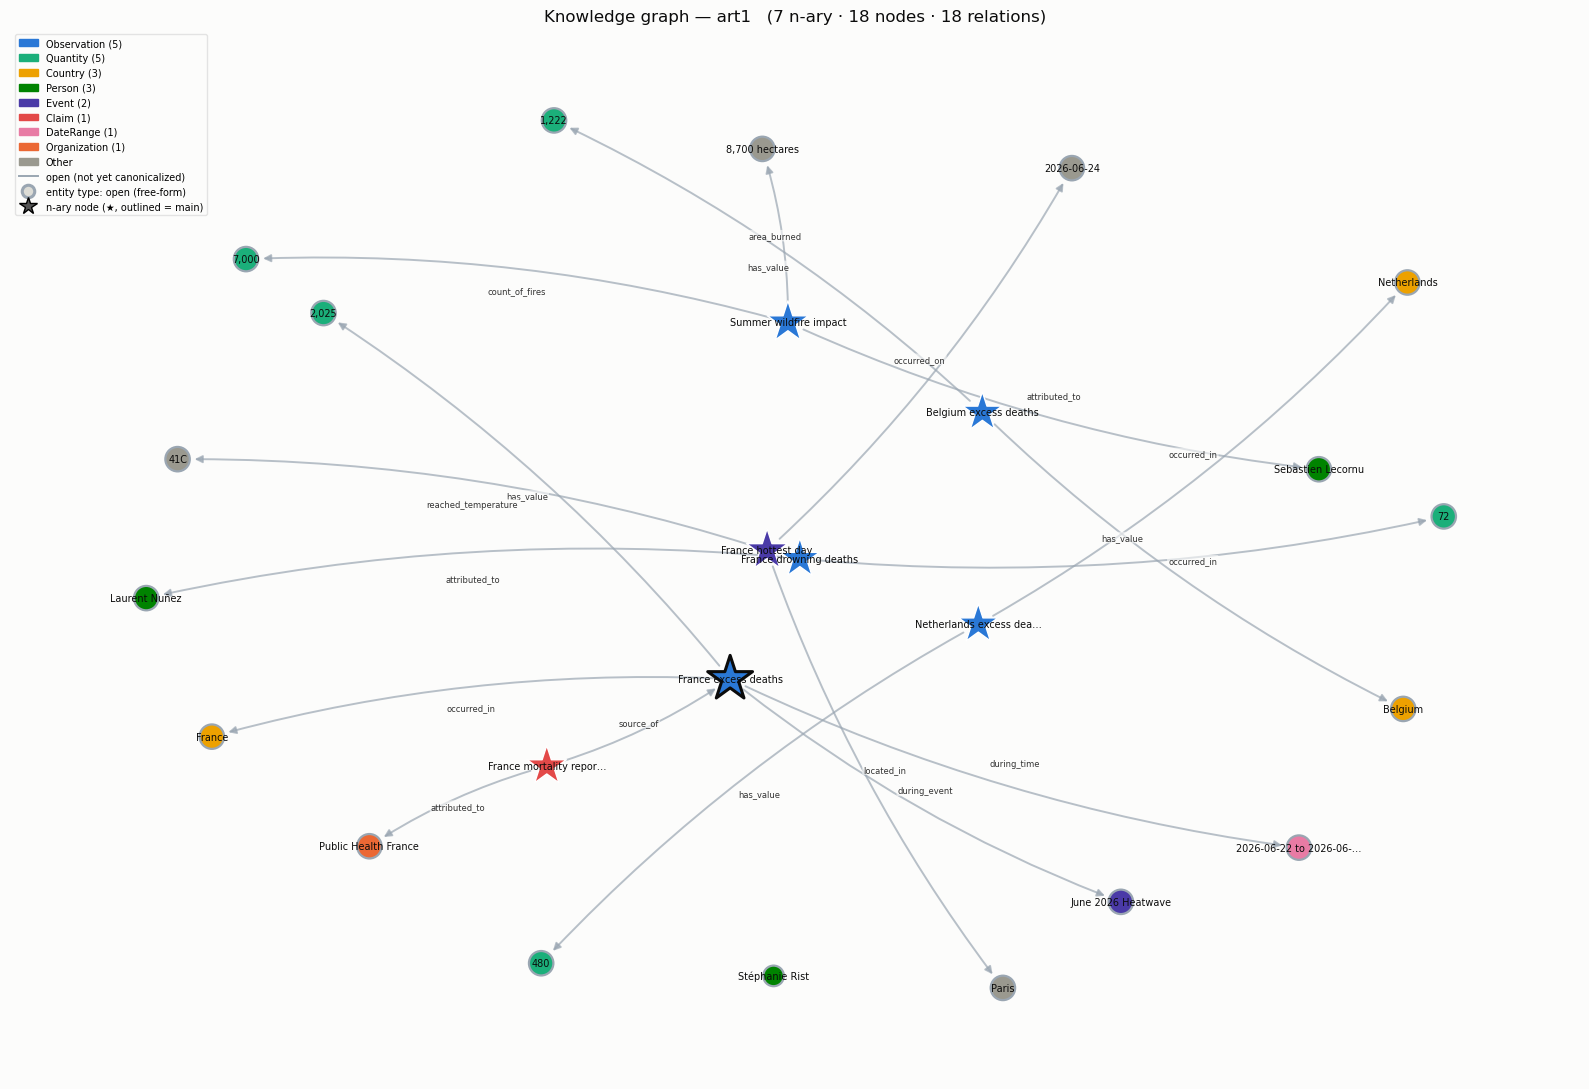

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

def kg_stem(aid, nodes=None):
    """Output basename keyed to the SOURCE file (LAST_SRC), so different views don't clobber each other:
         *_e2e      — single-call baseline  (nary_graph_e2e*.json, nb6c)
         *_reified  — staged event-centric  (nary_graph*.json / reified / hubs, nb6b/nb7b)
         kg_<id>    — binary triples        (relations_ext*.json, nb7)"""
    s = LAST_SRC
    if "e2e" in s:
        return "e2e/viz/kg"
    if any(t in s for t in ("nary_graph", "reified", "hubs")):
        return "two_staged/viz/kg_reified"
    return "two_staged/viz/kg_binary"

def draw_static(aid, nodes, edges, show_edge_labels=SHOW_EDGE_LABELS, save=True, show=True):
    G = nx.MultiDiGraph()
    for i, n in nodes.items():
        G.add_node(i, **n)
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            G.add_edge(e["s"], e["o"], property=e["property"], source=e["source"])

    deg = dict(G.degree())
    pos = nx.spring_layout(G, seed=LAYOUT_SEED, k=1.6 / max(len(G) ** 0.5, 1))
    n_nary = sum(1 for i in nodes if nodes[i].get("is_nary"))

    fig, ax = plt.subplots(figsize=STATIC_FIGSIZE)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE); ax.axis("off")

    # nodes grouped by kind so n-ary nodes (star) and literals (square) get their own marker & size
    def kind(i):
        n = nodes[i]
        return "nary" if n.get("is_nary") else ("lit" if n.get("is_lit") else "ent")
    for grp, marker, base in (("ent", "o", 220), ("nary", "*", 700), ("lit", "s", 150)):
        ids = [i for i in G.nodes() if kind(i) == grp]
        if not ids:
            continue
        if grp == "ent":                                           # entity border = TYPE SOURCE; width = is_main
            ecolors = [type_src_border(nodes[i].get("type_source")) for i in ids]
            widths  = [2.6 if nodes[i].get("is_main") else 1.6 for i in ids]
        else:                                                      # n-ary / literal: border just marks is_main
            ecolors = [INK if nodes[i].get("is_main") else "white" for i in ids]
            widths  = [2.2 if nodes[i].get("is_main") else 1.0 for i in ids]
        nx.draw_networkx_nodes(
            G, pos, ax=ax, nodelist=ids, node_shape=marker,
            node_color=[node_color(nodes[i]["type"]) for i in ids],
            node_size=[base + 90 * deg.get(i, 0) for i in ids],
            edgecolors=ecolors, linewidths=widths)

    # edges grouped by source bucket (schema.org / vocab / open), each with its colour + dash style
    for bucket, (color, style) in EDGE_STYLE.items():
        elist = [(u, v) for u, v, d in G.edges(data=True) if edge_bucket(d.get("source")) == bucket]
        if elist:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=elist, edge_color=color, style=style,
                width=1.4, alpha=0.7, arrows=True, arrowsize=11,
                connectionstyle="arc3,rad=0.08", node_size=600)

    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=7, font_color=INK,
        labels={i: (nodes[i]["label"][:22] + ("…" if len(nodes[i]["label"]) > 22 else "")) for i in G.nodes()})

    if show_edge_labels:
        agg = {}                                                   # aggregate parallel edges' labels per (u,v)
        for u, v, d in G.edges(data=True):
            agg.setdefault((u, v), []).append(d.get("property") or "")
        nx.draw_networkx_edge_labels(
            G, pos, ax=ax, font_size=6, font_color="#333333", rotate=False,
            bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.6),
            edge_labels={k: ", ".join(dict.fromkeys(v)) for k, v in agg.items()})

    handles = [mpatches.Patch(color=c, label=f"{t} ({type_counts[t]})") for t, c in TYPE_COLORS.items()]
    if HAS_OTHER:
        handles.append(mpatches.Patch(color=OTHER_COLOR, label="Other"))
    # only show edge-source legend entries that actually occur in this graph
    present = {edge_bucket(e["source"]) for e in edges}
    edge_legend = [("open", OPEN_EDGE, "-", "open (not yet canonicalized)"),
                   ("schema.org", SCHEMA_EDGE, "-", "schema.org property"),
                   ("vocab", EX_EDGE, "--", "vocab (minted property)")]
    handles += [plt.Line2D([0], [0], color=col, lw=1.4, ls=ls, label=lab)
                for b, col, ls, lab in edge_legend if b in present]
    # entity TYPE-SOURCE ring legend (node border colour) — only buckets that occur
    present_tsrc = {type_src_bucket(nodes[i].get("type_source"))
                    for i in nodes if not nodes[i].get("is_nary") and not nodes[i].get("is_lit")}
    tsrc_legend = [("schema.org", SCHEMA_EDGE, "entity type: schema.org"),
                   ("vocab", EX_EDGE, "entity type: vocab (minted)"),
                   ("open", OPEN_EDGE, "entity type: open (free-form)")]
    handles += [plt.Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="#dcdcd6",
                           markeredgecolor=col, markeredgewidth=2.2, markersize=9, label=lab)
                for b, col, lab in tsrc_legend if b in present_tsrc]
    if n_nary:
        handles.append(plt.Line2D([0], [0], marker="*", color="none", markerfacecolor="#555",
                                   markersize=13, label="n-ary node (★, outlined = main)"))
        subtitle = f"{n_nary} n-ary · {len(nodes) - n_nary} nodes · {len(edges)} relations"
    else:
        subtitle = f"{len(nodes)} entities · {len(edges)} relations"
    ax.legend(handles=handles, loc="upper left", fontsize=7, frameon=True,
              facecolor=SURFACE, edgecolor="#dddddd")
    ax.set_title(f"Knowledge graph — {aid}   ({subtitle})", fontsize=12, color=INK)
    fig.tight_layout()

    if save:
        out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.png"; out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out, dpi=150, facecolor=SURFACE, bbox_inches="tight")
        print("saved", out)
    if show:
        plt.show()
    else:
        plt.close(fig)

draw_static(ARTICLE_ID, nodes, edges)

## 4. Interactive figure (pyvis) → `results/<id>/kg_<id>.html`

Drag nodes, zoom, and hover — node tooltip shows its type + aliases, edge tooltip shows the property,
its source, the originating relation phrase(s), and the evidence span. The HTML is **self-contained**
(vis.js inlined), so it opens offline.

In [9]:
FREEZE_AFTER_STABILIZE = True     # let physics settle once on open, then stop moving (freeze layout)

def draw_interactive(aid, nodes, edges, save=True, show=True):
    try:
        from pyvis.network import Network
    except ImportError:
        print("pyvis not installed — run the %pip cell above (the static PNG above still works).")
        return None
    # count degree for node sizing
    deg = Counter()
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            deg[e["s"]] += 1; deg[e["o"]] += 1

    try:
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True,
                      bgcolor=SURFACE, font_color=INK, cdn_resources="in_line", notebook=True)
    except TypeError:                                              # older pyvis without some kwargs
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True, bgcolor=SURFACE, font_color=INK)
    # Big, high-contrast labels (white halo so they read over edges), roomier layout, hover + nav buttons.
    # set_options wants a JSON string; json.dumps guarantees valid JSON (pyvis strips whitespace itself).
    net.set_options(json.dumps({
        "nodes": {"shape": "dot",
                  "font": {"size": NODE_FONT_SIZE, "face": "arial", "color": INK,
                           "strokeWidth": 4, "strokeColor": SURFACE}},
        "edges": {"arrows": {"to": {"enabled": True, "scaleFactor": 0.6}},
                  "color": {"inherit": False, "opacity": 0.8},
                  "smooth": {"enabled": True, "type": "dynamic"},
                  "font": {"size": EDGE_FONT_SIZE, "face": "arial", "color": "#333333",
                           "strokeWidth": 5, "strokeColor": SURFACE, "align": "middle"},
                  "width": 1.5},
        "physics": {"barnesHut": {"gravitationalConstant": -32000, "centralGravity": 0.2,
                                  "springLength": PYVIS_SPRING, "springConstant": 0.02,
                                  "damping": 0.5, "avoidOverlap": 0.7},
                    "minVelocity": 0.75, "stabilization": {"enabled": True, "iterations": 400, "fit": True}},
        "interaction": {"hover": True, "tooltipDelay": 120, "navigationButtons": True, "keyboard": True},
    }))

    for i, n in nodes.items():
        if n.get("is_nary"):                                       # n-ary node -> big star; main events outlined
            title = f'{n["label"]}  ·  {n.get("nary_kind")} / {n.get("nary_type")}'
            if n.get("nary_type_parent"):                          # grounded subtype: type ⊑ parent [source]
                title += f'  ⊑ {n.get("nary_type_parent")} [{n.get("nary_type_source")}]'
            if n.get("is_main"): title += "  ·  MAIN"
            if n.get("evidence"): title += f'\nevidence: {n["evidence"]}'
            net.add_node(i, label=n["label"], title=title, color=node_color(n["type"]),
                         shape="star", size=26 + 4 * deg.get(i, 0),
                         borderWidth=(5 if n.get("is_main") else 2),
                         borderWidthSelected=6)
        elif n.get("is_lit"):                                      # literal value -> small box
            net.add_node(i, label=n["label"], title=n["label"], color="#e9e7df",
                         shape="box", size=10)
        else:                                                      # entity -> dot; border = TYPE SOURCE
            src = n.get("type_source")
            etitle = f'{n["label"]}  ·  type: {n["type"]}  [{type_src_bucket(src)}]'
            if n.get("type_parent"): etitle += f'  ⊑ {n["type_parent"]}'
            net.add_node(i, label=n["label"], title=etitle, shape="dot",
                         color={"background": node_color(n["type"]), "border": type_src_border(src)},
                         size=14 + 5 * deg.get(i, 0), borderWidth=3, borderWidthSelected=5)
    for e in edges:
        if e["s"] not in nodes or e["o"] not in nodes:
            continue
        tip = f'{e["property"]}  [{e["source"]}]'                  # source: open / schema.org / vocab
        if e["phrases"]:  tip += f'\nphrase(s): {", ".join(e["phrases"])}'
        if e["evidence"]: tip += f'\nevidence: {e["evidence"]}'
        net.add_edge(e["s"], e["o"], label=e["property"] or "", title=tip,
                     color=edge_color(e["source"]), dashes=edge_dashed(e["source"]),
                     arrows="to")

    out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.html"; out.parent.mkdir(parents=True, exist_ok=True)
    if save:
        try:
            net.write_html(str(out), notebook=False)              # newer pyvis
        except Exception:
            net.save_graph(str(out))
        if FREEZE_AFTER_STABILIZE:
            # Inject a snippet so the graph settles once on open, then turns physics OFF and holds
            # that layout (nodes stay draggable, but nothing drifts). The setTimeout is a fallback in
            # case the stabilization event has already fired by the time this script runs.
            freeze = (
                '\n<script type="text/javascript">\n'
                '  (function () {\n'
                '    if (typeof network === "undefined") return;\n'
                '    var stop = function () { network.setOptions({ physics: false }); };\n'
                '    network.on("stabilizationIterationsDone", stop);\n'
                '    setTimeout(stop, 4000);\n'
                '  })();\n'
                '</script>\n'
            )
            html = out.read_text()
            out.write_text(html.replace("</body>", freeze + "</body>", 1) if "</body>" in html
                           else html + freeze)
        print("saved", out)
    if show:
        from IPython.display import IFrame, display
        display(IFrame(src=str(out), width="100%", height="780px"))
    return out

draw_interactive(ARTICLE_ID, nodes, edges)

saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art1/e2e/viz/kg.html


PosixPath('/Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art1/e2e/viz/kg.html')

## 5. Triples table (subject → property → object)

In [10]:
# Plain, sorted listing of every edge — the KG as text, for a quick read / copy.
def print_triples(nodes, edges):
    rows = sorted(edges, key=lambda e: (e.get("property") or "", nodes.get(e["s"], {}).get("label", "")))
    print(f"{len(rows)} relations\n" + "-" * 90)
    for e in rows:
        s = nodes.get(e["s"], {}).get("label", e.get("s_text") or e["s"])
        o = nodes.get(e["o"], {}).get("label", e.get("o_text") or e["o"])
        tag = edge_bucket(e["source"])                             # open / schema.org / vocab
        conf = f'  ({e["confidence"]})' if e.get("confidence") is not None else ""
        print(f'  {s}  --{e["property"]} [{tag}]-->  {o}{conf}')

print_triples(nodes, edges)

18 relations
------------------------------------------------------------------------------------------
  Summer wildfire impact  --area_burned [open]-->  8,700 hectares  (1.0)
  France drowning deaths  --attributed_to [open]-->  Laurent Nuñez  (1.0)
  France mortality report  --attributed_to [open]-->  Public Health France  (1.0)
  Summer wildfire impact  --attributed_to [open]-->  Sebastien Lecornu  (1.0)
  Summer wildfire impact  --count_of_fires [open]-->  7,000  (1.0)
  France excess deaths  --during_event [open]-->  June 2026 Heatwave  (1.0)
  France excess deaths  --during_time [open]-->  2026-06-22 to 2026-06-28  (1.0)
  Belgium excess deaths  --has_value [open]-->  1,222  (1.0)
  France drowning deaths  --has_value [open]-->  72  (1.0)
  France excess deaths  --has_value [open]-->  2,025  (1.0)
  Netherlands excess deaths  --has_value [open]-->  480  (1.0)
  France hottest day  --located_in [open]-->  Paris  (1.0)
  Belgium excess deaths  --occurred_in [open]-->  Belgium  (1.0

## 6. Batch — render every article

In [11]:
# Render the static PNG (and interactive HTML) for every article that has an nb7 relations file.
# No inline display — just writes results/<id>/kg_<id>.png and .html.
_articles = sorted({p.relative_to(RESULTS_DIR).parts[0] for name in REL_FILES for p in RESULTS_DIR.glob(f"*/{name}")})
print("rendering", len(_articles), "article(s):", _articles)
for aid in _articles:
    n, e, _ = load_kg(aid)
    if not n:
        print(f"  {aid}: no connected entities, skipped"); continue
    # rebuild the per-article type colour map so each figure is self-consistent
    global TYPE_COLORS, HAS_OTHER, type_counts
    type_counts = Counter(v["type"] for v in n.values())
    TYPE_COLORS, HAS_OTHER = build_type_colors(n)
    draw_static(aid, n, e, save=True, show=False)
    draw_interactive(aid, n, e, save=True, show=False)
print("done")

rendering 4 article(s): ['art1', 'art2', 'art4', 'art5']
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art1/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art1/e2e/viz/kg.html
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art2/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art2/e2e/viz/kg.html
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art4/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art4/e2e/viz/kg.html
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art5/e2e/viz/kg.png
saved /Users/marwah/Documents/Thesis/TriplesExtractionFromWebLLMs/Phase2_LLM_Extraction/results/art5/e2e/viz/kg.html
done
